# 03 - Hub Prediction with Machine Learning

This notebook uses **Gradient Boosting** and **Random Forest** classifiers to predict:

1. **Which nodes become hubs** in the interest-based network (node-level prediction).
2. **When multiple hubs emerge** instead of a single dominant hub (network-level prediction).

### Methodology

The pipeline has three stages:

1. **Data generation** -- Run many interest-based Law-of-Few simulations with varied
   parameters (`k`, `interest_weight`). For each simulation, extract node-level features
   (centrality, interest profile, similarity metrics) and network-level features
   (density, modularity, homophily).

2. **Model training** -- Train a GradientBoostingClassifier on node features to predict
   `became_hub`, and a RandomForestClassifier on network features to predict `multi_hub`.

3. **Feature importance analysis** -- Identify which features are most predictive
   of hub formation and multi-hub emergence.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.models.hub_prediction import HubPredictionModel, run_hub_prediction_demo

## Parameter Configuration

| Parameter | Description | Value |
|-----------|-------------|-------|
| `n` | Nodes per simulation | 100 |
| `num_interests` | Dimensionality of interest vectors | 5 |
| `num_simulations` | Number of training simulations | 50 |
| `n_jobs` | Parallel workers for data generation | 4 |

Each simulation varies `k` (link cost) in [0.3, 0.7] and `interest_weight` in
[0.2, 0.8] to ensure the models learn across a range of conditions.

**Note:** For a quick demo, use `num_simulations=50`. For publication-quality results,
increase to 300+.

In [2]:
# Configuration -- reduce num_simulations for faster execution
NUM_SIMULATIONS = 50
N_JOBS = 4
N_NODES = 100
NUM_INTERESTS = 5

print(f"Will run {NUM_SIMULATIONS} simulations with {N_NODES} nodes each.")
print(f"Total node observations: ~{NUM_SIMULATIONS * N_NODES}")

Will run 50 simulations with 100 nodes each.
Total node observations: ~5000


## Step 1: Generate Training Data

Each simulation runs the `InterestBasedLawOfFewModel` with randomised parameters,
then extracts features from the initial and final network states. Nodes that end up
with high information **and** high in-degree are labelled as hubs.

In [3]:
hub_model = HubPredictionModel(n=N_NODES, num_interests=NUM_INTERESTS)

node_df, network_df = hub_model.generate_training_data(
    num_simulations=NUM_SIMULATIONS,
    vary_params=True,
    n_jobs=N_JOBS,
)

print(f"\nNode-level dataset:    {node_df.shape}")
print(f"Network-level dataset: {network_df.shape}")
print(f"Hub rate:              {node_df['became_hub'].mean():.2%}")
print(f"Multi-hub rate:        {network_df['multi_hub'].mean():.2%}")

Generating training data from 50 simulations...


100%|██████████| 200/200 [01:11<00:00,  2.78it/s]


Hub rate: 1.76%, Multi-hub rate: 32.00%

Node-level dataset:    (5000, 21)
Network-level dataset: (50, 17)
Hub rate:              1.76%
Multi-hub rate:        32.00%


In [4]:
# Inspect the feature distributions
node_df.describe().T

,count,mean,std,min,25%,50%,75%,max
initial_info,5000.0,0.049427,1.525379e-01,0.000000,0.000000,0.000000,0.000000,0.699893
initial_out_degree,5000.0,2.484600,1.551078e+00,0.000000,1.000000,2.000000,3.000000,11.000000
initial_in_degree,5000.0,2.484600,1.547334e+00,0.000000,1.000000,2.000000,3.000000,10.000000
initial_degree,5000.0,4.969200,2.186048e+00,0.000000,3.000000,5.000000,6.000000,16.000000
betweenness,5000.0,0.030495,2.936225e-02,0.000000,0.007121,0.023621,0.045368,0.241257
closeness,5000.0,0.174814,6.926724e-02,0.000000,0.159233,0.190559,0.216830,0.350622
interest_norm,5000.0,1.000000,7.599099e-17,1.000000,1.000000,1.000000,1.000000,1.000000
interest_variance,5000.0,0.160096,4.291855e-02,0.003592,0.138018,0.175892,0.194576,0.200000
interest_range,5000.0,1.094182,1.910488e-01,0.165216,1.002110,1.135620,1.227364,1.406467
interest_extremity,5000.0,0.372054,3.876966e-02,0.228628,0.346438,0.374517,0.399840,0.479985


## Step 2: Train the Hub Prediction Model

### Node-Level Model (GradientBoosting)
Predicts whether an individual node becomes a hub based on its initial centrality,
interest profile, and similarity to other nodes.

### Network-Level Model (RandomForest)
Predicts whether a simulation produces multiple hubs based on aggregate network
properties like density, modularity, and interest diversity.

In [5]:
# Train node-level hub prediction model
node_acc, node_importance = hub_model.train_node_model(node_df)
print(f"\nNode-level test accuracy: {node_acc:.4f}")

Hub prediction test accuracy: 0.9780
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1474
           1       0.00      0.00      0.00        26

    accuracy                           0.98      1500
   macro avg       0.49      0.50      0.49      1500
weighted avg       0.97      0.98      0.97      1500


Node-level test accuracy: 0.9780


In [6]:
# Train network-level multi-hub prediction model
net_acc, net_importance = hub_model.train_multi_hub_model(network_df)
print(f"\nNetwork-level test accuracy: {net_acc:.4f}")

Multi-hub prediction test accuracy: 0.8667
              precision    recall  f1-score   support

           0       0.83      1.00      0.91        10
           1       1.00      0.60      0.75         5

    accuracy                           0.87        15
   macro avg       0.92      0.80      0.83        15
weighted avg       0.89      0.87      0.86        15


Network-level test accuracy: 0.8667


## Step 3: Feature Importance Analysis

Which features matter most for predicting hub formation? Understanding this tells us
what structural and interest-based properties drive the emergence of hubs in
interest-heterogeneous networks.

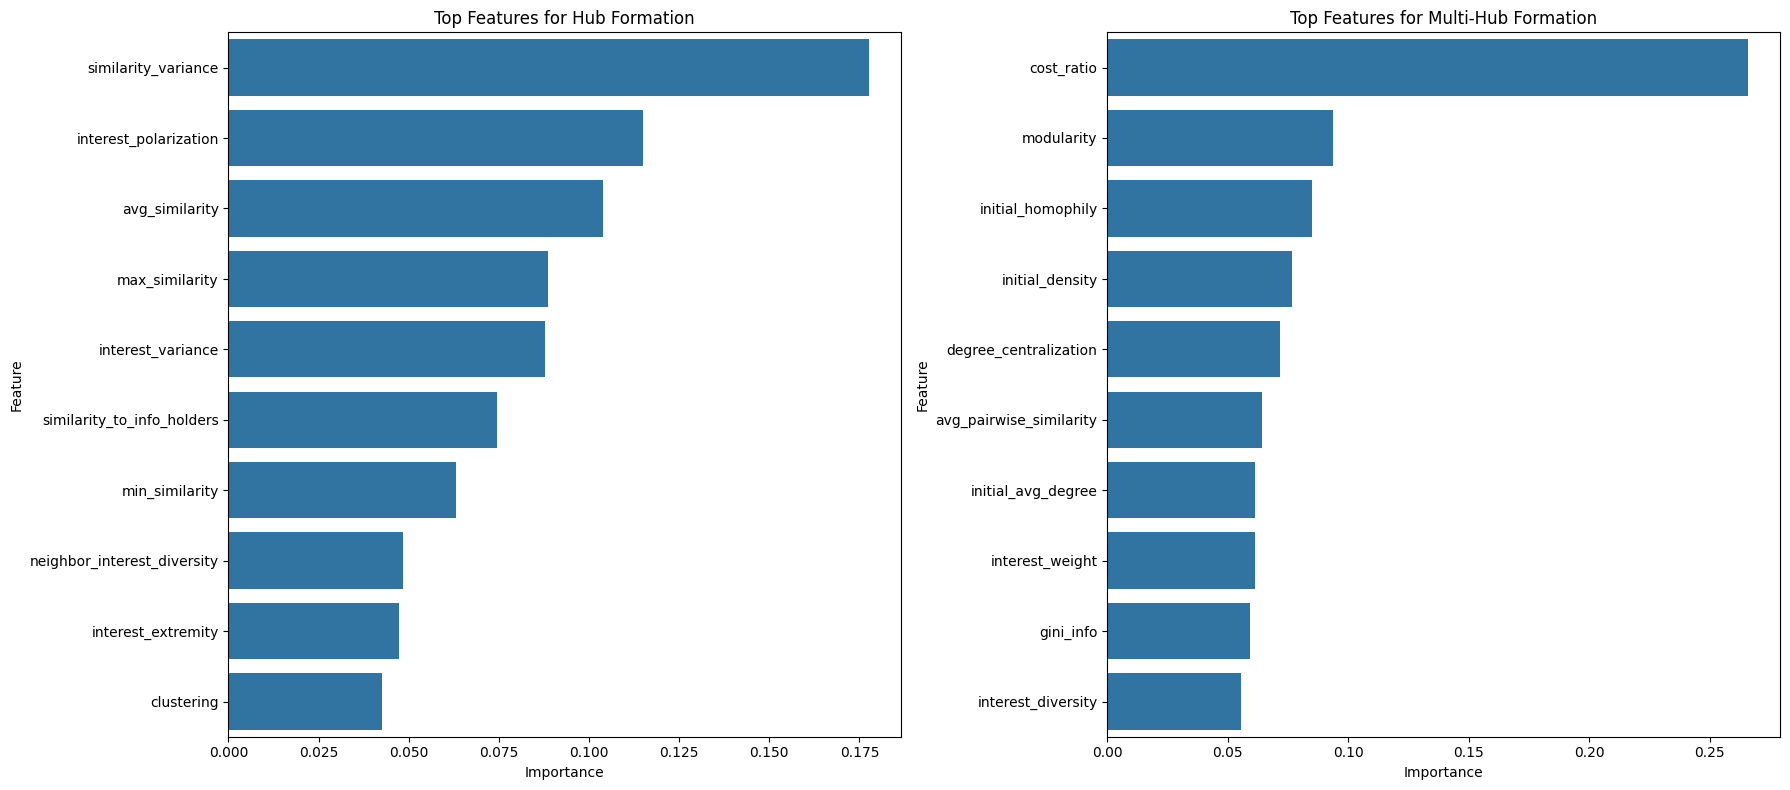

In [7]:
fig = hub_model.analyze_feature_importance(node_importance, net_importance)
plt.show()

In [8]:
# Display top features in table form
print("\n=== Top 10 Features for Hub Prediction ===")
print(node_importance.head(10).to_string(index=False))

print("\n=== Top 10 Features for Multi-Hub Prediction ===")
print(net_importance.head(10).to_string(index=False))


=== Top 10 Features for Hub Prediction ===
                    Feature  Importance
        similarity_variance    0.177656
      interest_polarization    0.114896
             avg_similarity    0.103796
             max_similarity    0.088714
          interest_variance    0.087721
 similarity_to_info_holders    0.074499
             min_similarity    0.063092
neighbor_interest_diversity    0.048388
         interest_extremity    0.047399
                 clustering    0.042621

=== Top 10 Features for Multi-Hub Prediction ===
                Feature  Importance
             cost_ratio    0.265803
             modularity    0.093720
      initial_homophily    0.085033
        initial_density    0.076798
  degree_centralization    0.071830
avg_pairwise_similarity    0.064359
     initial_avg_degree    0.061370
        interest_weight    0.061228
              gini_info    0.059368
     interest_diversity    0.055637


## Hub vs Non-Hub Feature Comparison

We compare the distributions of key features between nodes that became hubs and
those that did not, to visually confirm the model's learned patterns.

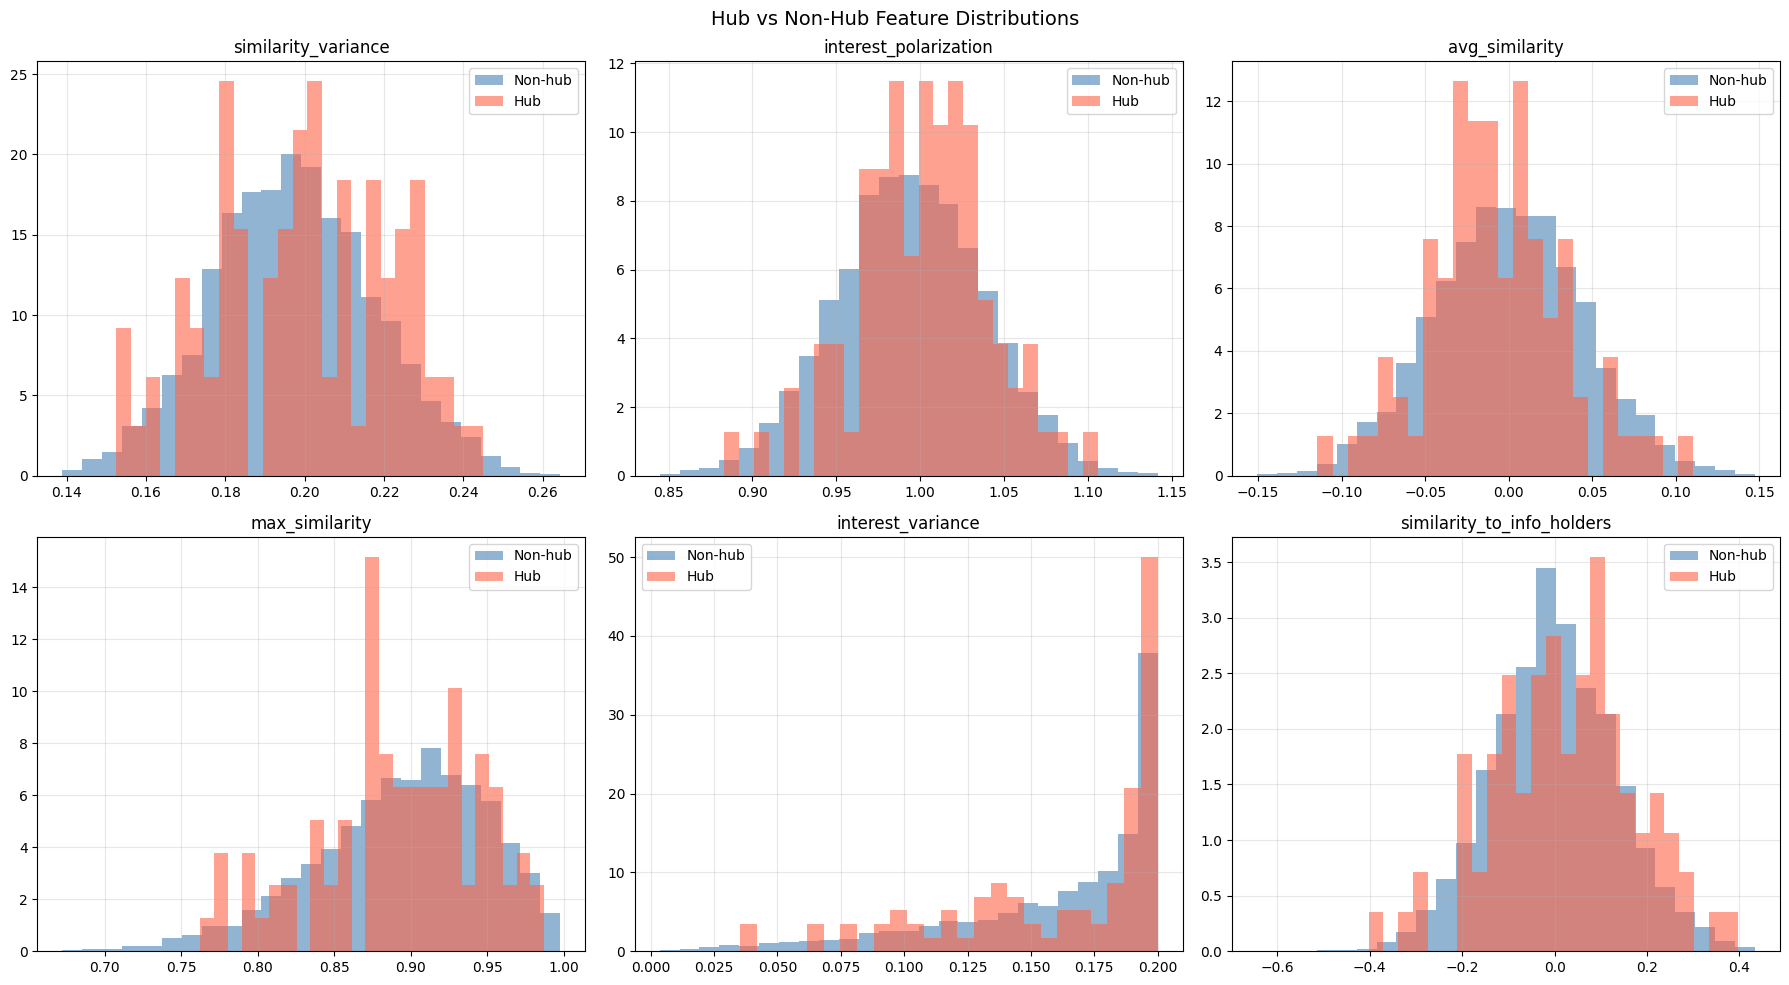

In [9]:
top_features = node_importance.head(6)['Feature'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, feat in zip(axes.flat, top_features):
    if feat in node_df.columns:
        for label, color in [(0, 'steelblue'), (1, 'tomato')]:
            subset = node_df[node_df['became_hub'] == label][feat].dropna()
            ax.hist(subset, bins=25, alpha=0.6, color=color,
                    label='Hub' if label else 'Non-hub', density=True)
        ax.set_title(feat)
        ax.legend()
        ax.grid(alpha=0.3)

plt.suptitle('Hub vs Non-Hub Feature Distributions', fontsize=14)
plt.tight_layout()
plt.show()